# Market calibration: can a model beat the crowd?

STATS C161 midterm, market part (Aaron). Full write-up with the reasoning: `reports/midterm/market_writeup.md`.

**Question.** A Polymarket price is the crowd's probability that something happens. Is it calibrated in our four
categories (Politics, Technology, Entertainment, Economy), and can a model using information available at the time beat it?

**Answer.** Yes, it is well calibrated; a faint favorite-longshot pattern appears only at extreme prices and is not stable;
no model we built beats the price out of sample.

Every number here comes from `src/market_analysis.py`, the same code that writes `reports/tables/` and the figures,
so this notebook, the tables and the slides cannot disagree. Rebuild everything with `make market`.

In [1]:
import sys, warnings, json
warnings.filterwarnings('ignore')
sys.path.insert(0, '../src')
import pandas as pd
import market_analysis as ma
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.precision', 3)

d = ma.load_sample()      # market x horizon rows with a trade within 72h of the time point
d.groupby('horizon_h').agg(markets=('slug', 'size'), events=('event_slug', 'nunique'), yes_rate=('y', 'mean'))

,markets,events,yes_rate
horizon_h,,,
6,5919,1628,0.211
24,5805,1610,0.202
72,5645,1561,0.191
168,4178,1265,0.199


## 0. Where the price comes from

The price at each time point is the last trade before it (No trades converted with 1 - price). The hourly order book
recorded only about a fifth of these markets, so it is used as a check: where both exist, they agree closely.

In [2]:
ma.price_check(d)

{'rows_with_book': 2915,
 'share_with_book': 0.13528565461549172,
 'corr': 0.9177170781036962,
 'median_abs_gap': 0.009499999999999998}

## 1. Calibration

Calibration slope = coefficient on logit(price) in a logistic regression of the outcome. 1 = calibrated;
above 1 = prices too close to 50/50 (long shots overpriced, the favorite-longshot bias); below 1 = overconfident.
The 95% intervals resample whole events, because markets in one event are dependent.

In [3]:
slopes = ma.calibration_slopes(d)
slopes

,horizon_h,category,n,events,intercept,slope,slope_lo,slope_hi,brier,yes_rate
0,6,All,5919,1628,-0.003,1.078,1.010,1.159,0.038,0.211
1,6,Politics,2542,855,-0.065,1.069,0.974,1.226,0.028,0.210
2,6,Technology,740,210,-0.193,1.078,0.916,1.476,0.031,0.204
3,6,Entertainment,1875,411,0.112,1.169,1.046,1.331,0.047,0.233
4,6,Economy,762,152,-0.103,0.929,0.785,1.130,0.059,0.169
5,24,All,5805,1610,0.025,1.050,0.989,1.127,0.049,0.202
6,24,Politics,2574,856,-0.047,1.034,0.948,1.150,0.043,0.206
7,24,Technology,729,203,-0.064,1.111,0.976,1.292,0.038,0.192
8,24,Entertainment,1753,399,0.164,1.124,1.002,1.294,0.054,0.214
9,24,Economy,749,152,-0.076,0.917,0.767,1.136,0.068,0.171


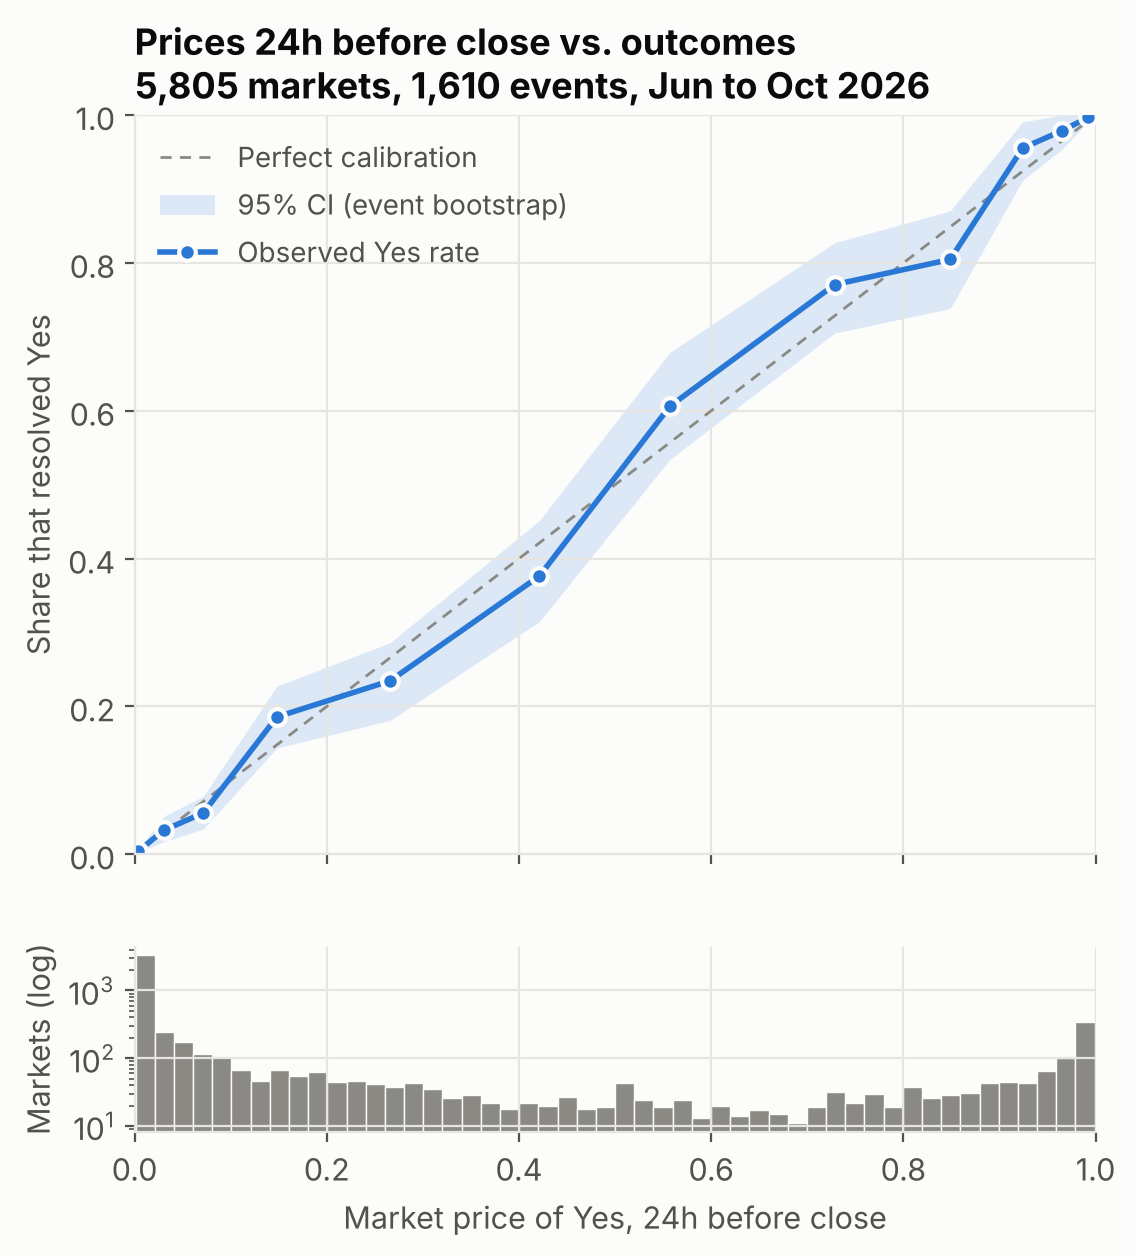

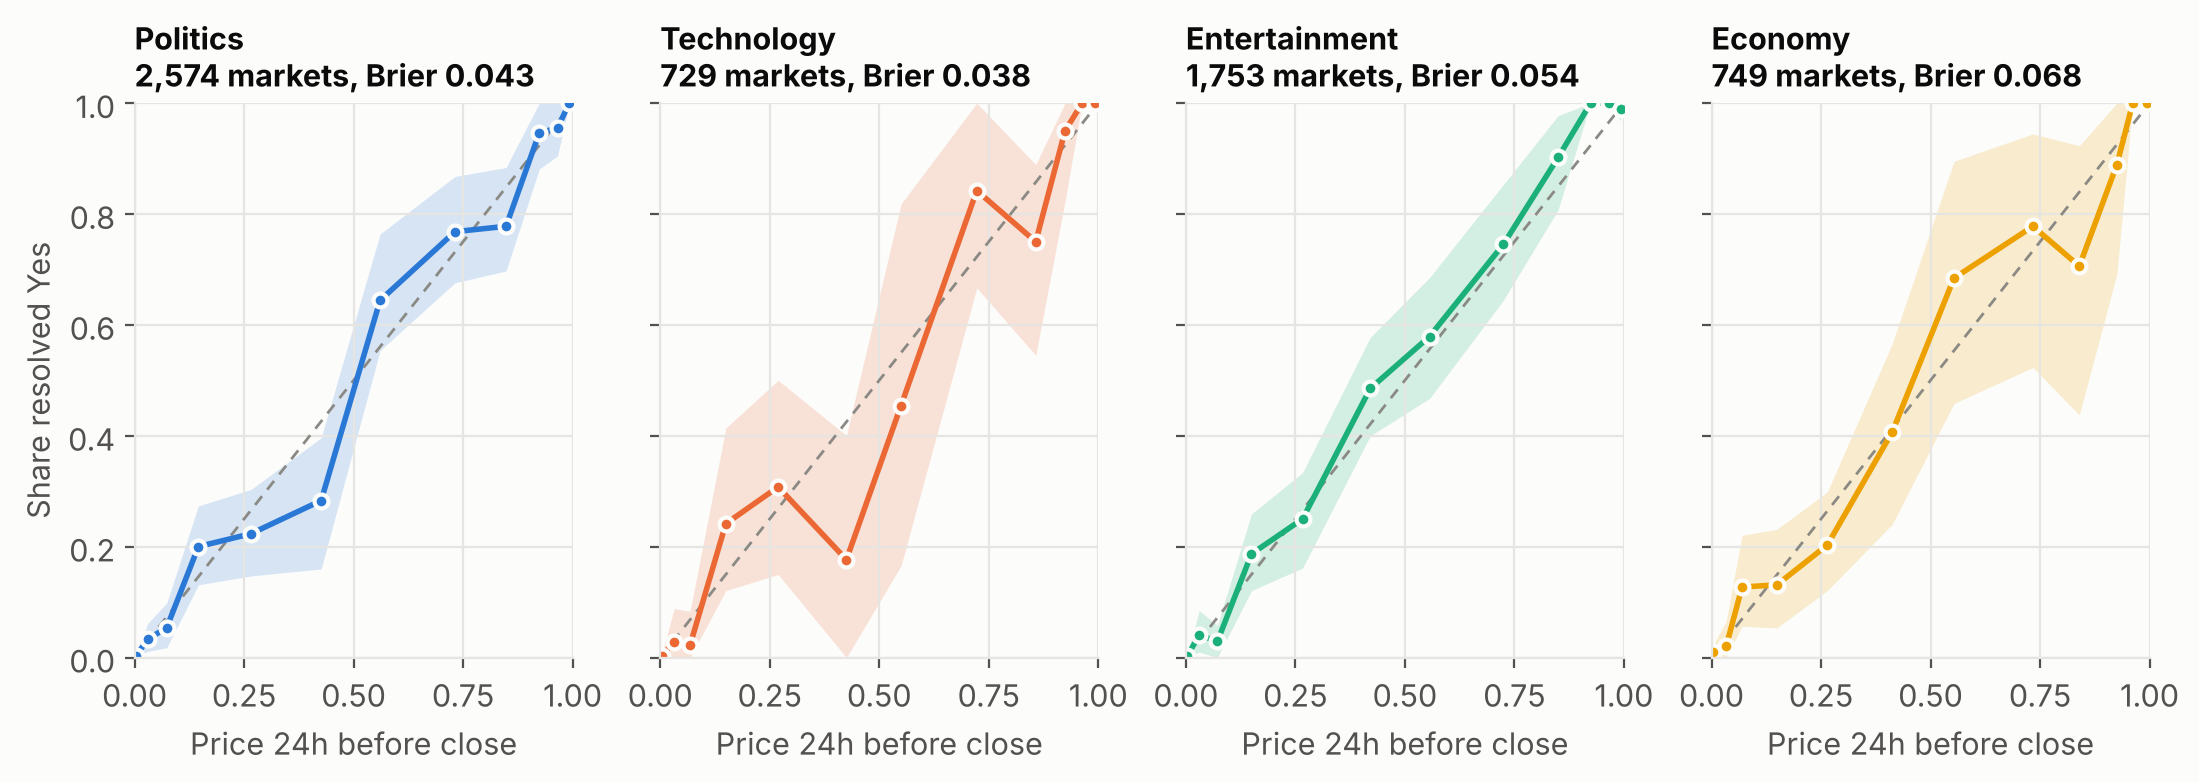

In [4]:
display(Image('../reports/figures/fig1_calibration_24h.png', width=520))
display(Image('../reports/figures/fig2_calibration_by_category.png'))

## 2. Where does the slope above 1 come from?

Drop near-certain prices (under 2c or over 98c), then look month by month (24h before close).

In [5]:
cuts, months = ma.robustness(d)
display(cuts)
months

,cut,horizon_h,n,events,slope,slope_lo,slope_hi
0,all prices,6,5919,1628,1.078,1.001,1.155
1,2c to 98c,6,1750,729,1.002,0.894,1.109
2,all prices,24,5805,1610,1.050,0.980,1.121
3,2c to 98c,24,2203,928,1.012,0.919,1.105
4,all prices,72,5645,1561,1.036,0.964,1.108
5,2c to 98c,72,2528,1052,1.037,0.946,1.128
6,all prices,168,4178,1265,0.949,0.877,1.021
7,2c to 98c,168,2263,982,0.949,0.861,1.036


,month,n,events,slope,slope_lo,slope_hi
0,2026-06,1568,403,1.014,0.895,1.133
1,2026-07,480,178,0.927,0.713,1.142
2,2026-08,824,287,1.089,0.905,1.272
3,2026-09,1771,464,1.081,0.933,1.229
4,2026-10,1162,338,1.088,0.925,1.250


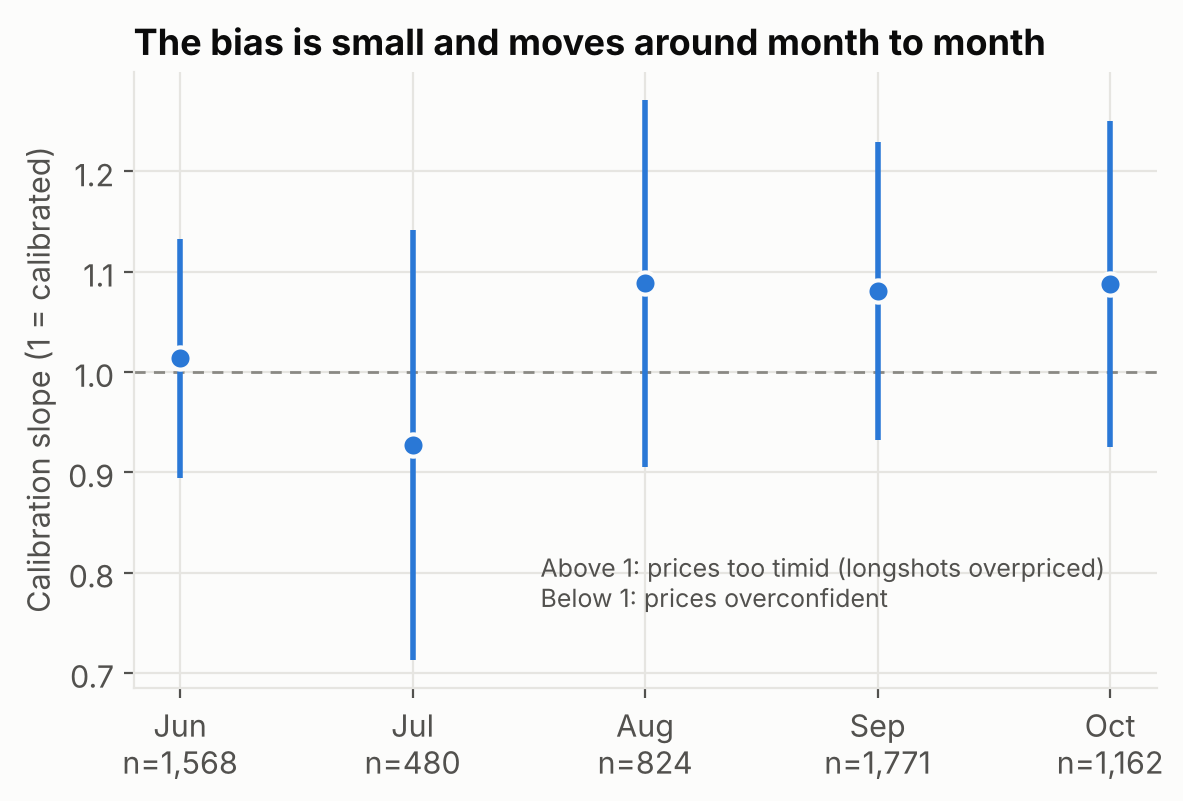

In [6]:
display(Image('../reports/figures/fig4_slope_by_month.png', width=560))

## 3. Accuracy over time and by category

In [7]:
slopes.pivot(index='category', columns='horizon_h', values='brier').loc[['All'] + ma.CATEGORIES]

horizon_h,6,24,72,168
category,,,,
All,0.038,0.049,0.057,0.074
Politics,0.028,0.043,0.056,0.078
Technology,0.031,0.038,0.043,0.061
Entertainment,0.047,0.054,0.060,0.070
Economy,0.059,0.068,0.069,0.077


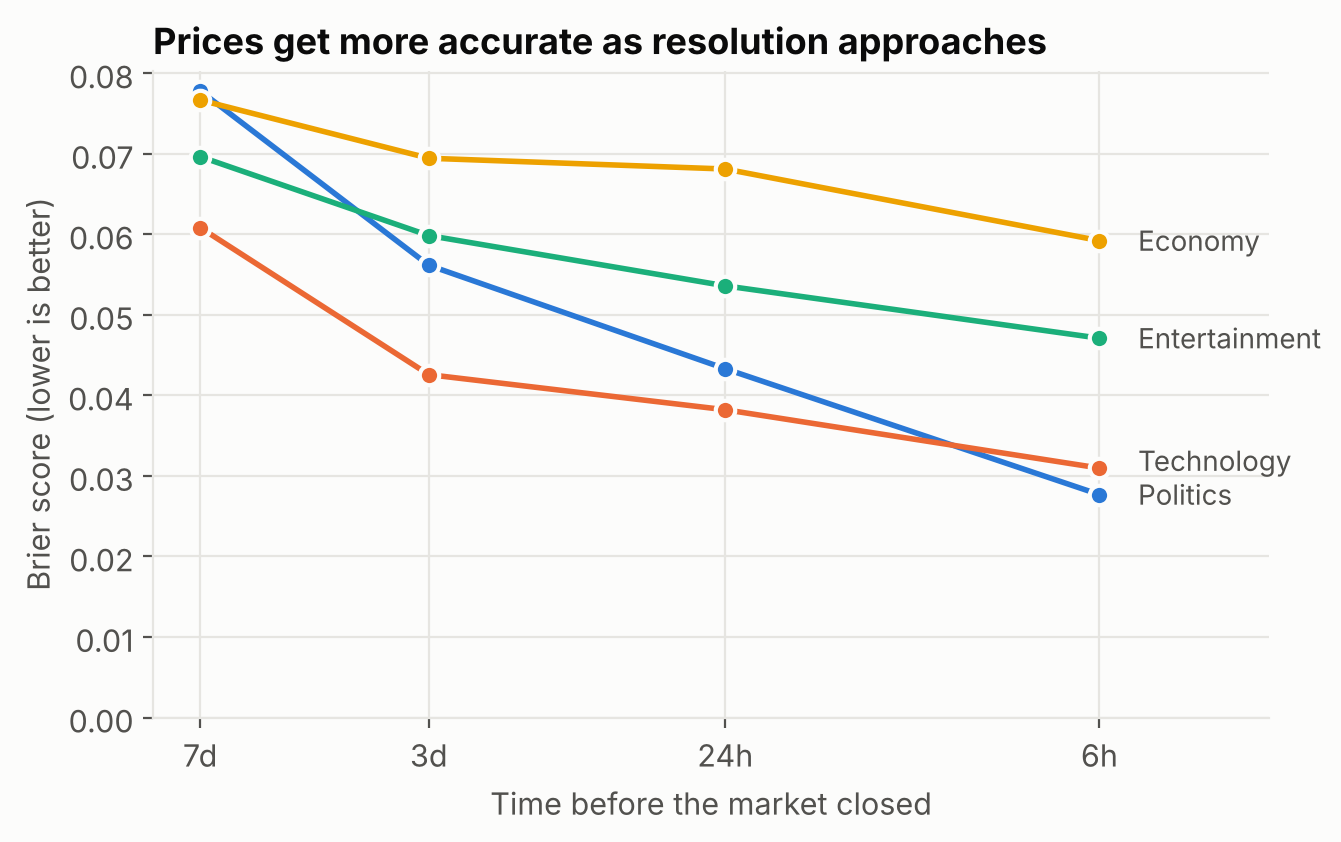

In [8]:
display(Image('../reports/figures/fig3_brier_by_horizon.png', width=600))

## 4. Models vs the market price

Train: events whose markets all closed before Sep 1, 2026. Test: the rest. No event is on both sides, and every feature
uses only trades before the time point.

- **Market price**: the baseline, price used as the probability
- **Logistic recalibration**: logit(price), its interaction with horizon and with category
- **Gradient boosting**: price plus 18 features known at the time

`d_brier` = model Brier minus market Brier (above 0 = worse than the market), with event-bootstrap 95% intervals.

In [9]:
te, preds, gb, sizes = ma.fit_models(d)
display(sizes)
results = ma.compare_models(te, preds)
results

,rows,markets,events
split,,,
test,10968,3511,860
train,10579,3215,841


,subset,horizon_h,model,n,brier,logloss,auc,d_brier,d_brier_lo,d_brier_hi
0,all prices,6,Market price,3052,0.041,0.134,0.983,NaN,NaN,NaN
1,all prices,6,Logistic recalibration,3052,0.041,0.137,0.981,4.133e-04,-2.918e-05,8.532e-04
2,all prices,6,Gradient boosting,3052,0.041,0.138,0.982,4.461e-04,-1.438e-03,2.128e-03
3,all prices,24,Market price,2985,0.051,0.170,0.971,NaN,NaN,NaN
4,all prices,24,Logistic recalibration,2985,0.052,0.172,0.970,5.275e-04,4.530e-05,1.036e-03
5,all prices,24,Gradient boosting,2985,0.052,0.174,0.970,5.517e-04,-1.697e-03,2.896e-03
6,all prices,72,Market price,2865,0.056,0.187,0.962,NaN,NaN,NaN
7,all prices,72,Logistic recalibration,2865,0.056,0.190,0.959,4.698e-04,-9.818e-06,9.346e-04
8,all prices,72,Gradient boosting,2865,0.059,0.197,0.958,2.976e-03,5.539e-04,5.597e-03
9,all prices,168,Market price,2066,0.078,0.262,0.923,NaN,NaN,NaN


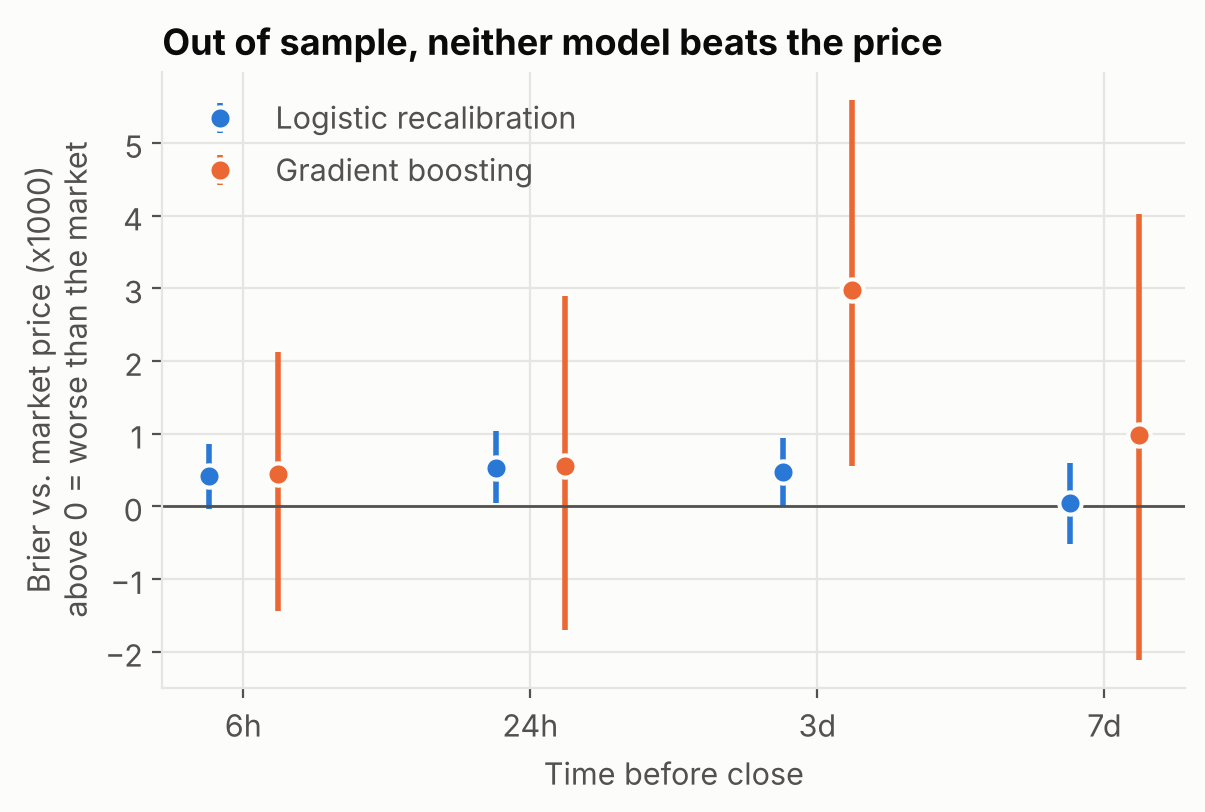

,feature,brier_increase
0,lp,1.015e-01
1,lvwap,3.990e-02
2,days_to_scheduled_end,1.606e-03
3,neg_risk,1.366e-03
4,market_age_days,5.895e-04
5,log_dollars_cum,4.901e-04
6,log_n_markets_in_event,2.574e-04
7,p_change_24h,2.357e-04


In [10]:
display(Image('../reports/figures/fig5_models_vs_market.png', width=560))
ma.feature_importance(gb, te).head(8)

## Takeaways

1. Prices are well calibrated in all four categories; between 2c and 98c the slope is about 1.00.
2. The slope above 1 near close comes from the extreme prices and changes from month to month, so it is not a stable bias.
3. Accuracy roughly doubles from 7 days to 6 hours before close; from 3 days out, Economy is the hardest category.
4. Neither model beats the price out of sample; the price carries almost all the information.

For the final: the price is a strong baseline, so an informed trader is one whose bets beat the price, not one who wins a lot.